In [88]:
# Cell 1: Import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from wordcloud import WordCloud

# NLP libraries
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Feature extraction
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Download necessary NLTK data (run once)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

# Plot settings
sns.set_style('whitegrid')
%matplotlib inline

In [162]:
# Cell 2: Load the two CSV files
fake_df = pd.read_csv('gossipcop_fake.csv')
real_df = pd.read_csv('gossipcop_real.csv')

print("Fake news shape:", fake_df.shape)
print("Real news shape:", real_df.shape)

Fake news shape: (5323, 4)
Real news shape: (16817, 4)


In [164]:
# Cell 3: Quick look at the data
print("Fake news columns:", fake_df.columns.tolist())
print("Real news columns:", real_df.columns.tolist())

display(fake_df.head(2))
display(real_df.head(2))

Fake news columns: ['id', 'news_url', 'title', 'tweet_ids']
Real news columns: ['id', 'news_url', 'title', 'tweet_ids']


,id,news_url,title,tweet_ids
0,gossipcop-2493749932,www.dailymail.co.uk/tvshowbiz/article-5874213/...,Did Miley Cyrus and Liam Hemsworth secretly ge...,284329075902926848\t284332744559968256\t284335...
1,gossipcop-4580247171,hollywoodlife.com/2018/05/05/paris-jackson-car...,Paris Jackson & Cara Delevingne Enjoy Night Ou...,992895508267130880\t992897935418503169\t992899...


,id,news_url,title,tweet_ids
0,gossipcop-882573,https://www.brides.com/story/teen-mom-jenelle-...,Teen Mom Star Jenelle Evans' Wedding Dress Is ...,912371411146149888\t912371528343408641\t912372...
1,gossipcop-875924,https://www.dailymail.co.uk/tvshowbiz/article-...,Kylie Jenner refusing to discuss Tyga on Life ...,901989917546426369\t901989992074969089\t901990...


In [166]:
# Cell 4: Data types and missing values overview
print("=== Fake news info ===")
fake_df.info()
print("\n=== Real news info ===")
real_df.info()

=== Fake news info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5323 entries, 0 to 5322
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         5323 non-null   object
 1   news_url   5067 non-null   object
 2   title      5323 non-null   object
 3   tweet_ids  5135 non-null   object
dtypes: object(4)
memory usage: 166.5+ KB

=== Real news info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16817 entries, 0 to 16816
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         16817 non-null  object
 1   news_url   16804 non-null  object
 2   title      16817 non-null  object
 3   tweet_ids  15759 non-null  object
dtypes: object(4)
memory usage: 525.7+ KB


In [168]:
# Cell 5: Add label column
# 0 = Real news, 1 = Fake news
fake_df['label'] = 1
real_df['label'] = 0

print("Fake sample labels:", fake_df['label'].head(2).tolist())
print("Real sample labels:", real_df['label'].head(2).tolist())

Fake sample labels: [1, 1]
Real sample labels: [0, 0]


In [170]:
# Cell 6: Combine, shuffle, and create master DataFrame
df = pd.concat([fake_df, real_df], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print("Combined dataset shape:", df.shape)
display(df.head(3))

Combined dataset shape: (22140, 5)


,id,news_url,title,tweet_ids,label
0,gossipcop-900533,https://stylecaster.com/beauty/lea-michele-hai...,Lea Michele’s Hairstylist’s Mixes Texture Spra...,943109597073756160\t943110188189569025\t943110...,0
1,gossipcop-1828135129,www.cbsnews.com/news/thomas-markle-prince-harr...,"Thomas Markle on Prince Harry, politics, and m...",801642150031216641\t803205108452487168\t803205...,1
2,gossipcop-899849,https://variety.com/2018/film/news/2019-sag-aw...,2019 SAG Award Nominations: See Full List of N...,940965108263604226\t940965107160379392\t940965...,0


In [172]:
# Cell 7: Identify main text column

if 'title' in df.columns:
    text_col = 'title'


In [174]:
# Cell 8: Handle missing values and duplicates
print("Missing values per column:")
print(df.isnull().sum())

#drop all columns except title and label
df.drop(columns=['id', 'news_url', 'tweet_ids'], inplace=True)


Missing values per column:
id              0
news_url      269
title           0
tweet_ids    1246
label           0
dtype: int64


In [176]:
print("Missing values per column:")
print(df.isnull().sum())
df.head

Missing values per column:
title    0
label    0
dtype: int64


<bound method NDFrame.head of                                                    title  label
0      Lea Michele’s Hairstylist’s Mixes Texture Spra...      0
1      Thomas Markle on Prince Harry, politics, and m...      1
2      2019 SAG Award Nominations: See Full List of N...      0
3      See Meghan Markle’s royal coat of arms and all...      0
4      Kylie Jenner visits shaman in Life of Kylie se...      0
...                                                  ...    ...
22135  Britney Spears Appears Terrified as Man Crashe...      0
22136                              American Music Awards      0
22137                  15 Great True Crime Documentaries      0
22138  Jennifer Garner's Trainer Launched a Wellness ...      1
22139      Matt LeBlanc turned down 'Modern Family' role      0

[22140 rows x 2 columns]>

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_10208/3848656245.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


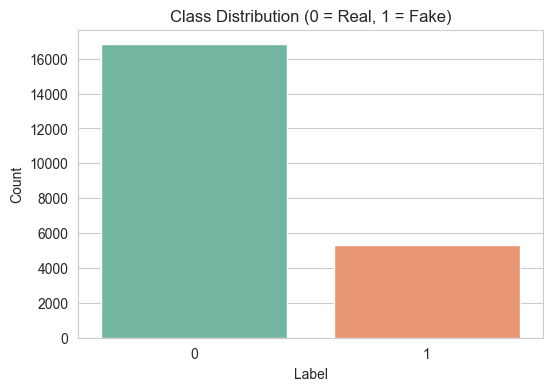

Label counts:
 label
0    16817
1     5323
Name: count, dtype: int64


In [178]:
# Cell 9: Class distribution
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Class Distribution (0 = Real, 1 = Fake)')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

print("Label counts:\n", df['label'].value_counts())

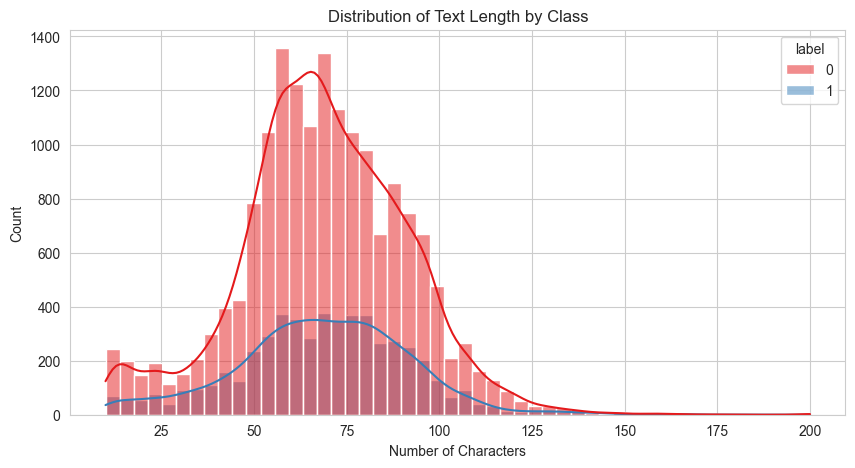

Text length statistics by label:
         count       mean        std   min   25%   50%   75%    max
label                                                              
0      16817.0  68.761372  22.596418  10.0  56.0  68.0  84.0  200.0
1       5323.0  68.525456  23.257223  10.0  54.0  69.0  84.0  182.0


In [180]:
# Cell 10: Text length (character count) analysis
df['text_len'] = df[text_col].astype(str).apply(len)

plt.figure(figsize=(10,5))
sns.histplot(data=df, x='text_len', hue='label', bins=50, kde=True, palette='Set1')
plt.title('Distribution of Text Length by Class')
plt.xlabel('Number of Characters')
plt.show()

print("Text length statistics by label:")
print(df.groupby('label')['text_len'].describe())

In [182]:
df.head

<bound method NDFrame.head of                                                    title  label  text_len
0      Lea Michele’s Hairstylist’s Mixes Texture Spra...      0        88
1      Thomas Markle on Prince Harry, politics, and m...      1        84
2      2019 SAG Award Nominations: See Full List of N...      0        63
3      See Meghan Markle’s royal coat of arms and all...      0        75
4      Kylie Jenner visits shaman in Life of Kylie se...      0        57
...                                                  ...    ...       ...
22135  Britney Spears Appears Terrified as Man Crashe...      0        95
22136                              American Music Awards      0        21
22137                  15 Great True Crime Documentaries      0        33
22138  Jennifer Garner's Trainer Launched a Wellness ...      1        83
22139      Matt LeBlanc turned down 'Modern Family' role      0        45

[22140 rows x 3 columns]>

In [184]:
df.to_csv('gossipcop.csv', index=False)

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_10208/3913268402.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='word_count', data=df, palette='Set3')


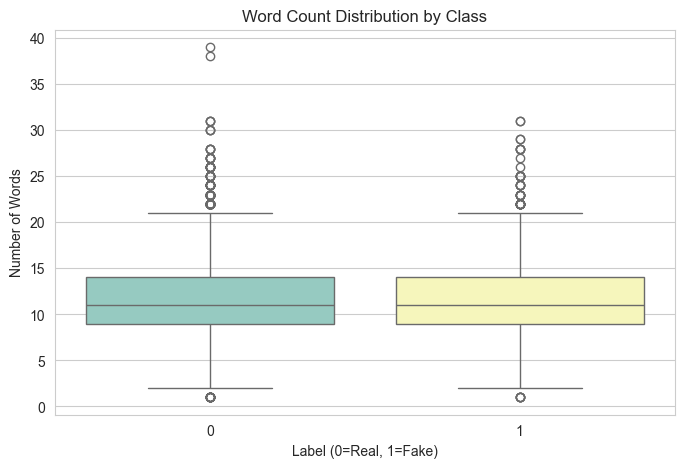

Word count statistics by label:
         count       mean       std  min  25%   50%   75%   max
label                                                          
0      16817.0  11.299875  3.878651  1.0  9.0  11.0  14.0  39.0
1       5323.0  11.057862  3.917703  1.0  9.0  11.0  14.0  31.0


In [186]:
# Cell 11: Word count analysis
df['word_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='word_count', data=df, palette='Set3')
plt.title('Word Count Distribution by Class')
plt.xlabel('Label (0=Real, 1=Fake)')
plt.ylabel('Number of Words')
plt.show()

print("Word count statistics by label:")
print(df.groupby('label')['word_count'].describe())

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_10208/475857849.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='unique_words', data=df, palette='pastel')


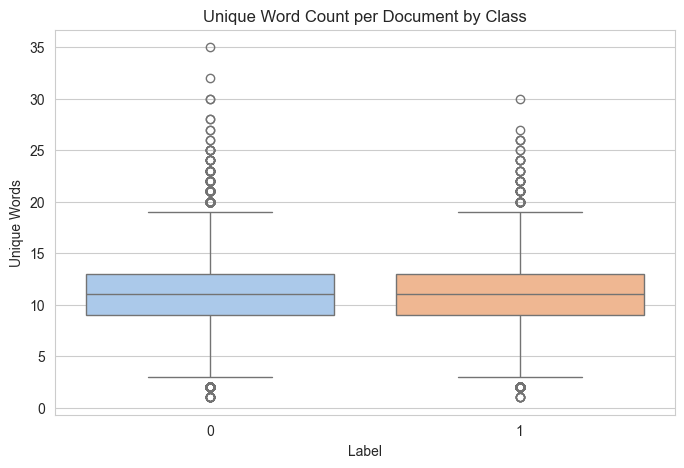

Unique word count statistics by label:
         count       mean       std  min  25%   50%   75%   max
label                                                          
0      16817.0  11.140929  3.732603  1.0  9.0  11.0  13.0  35.0
1       5323.0  10.903062  3.778188  1.0  9.0  11.0  13.0  30.0


In [188]:
# Cell 12: Unique word count (vocabulary size per document)
df['unique_words'] = df[text_col].astype(str).apply(lambda x: len(set(x.lower().split())))

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='unique_words', data=df, palette='pastel')
plt.title('Unique Word Count per Document by Class')
plt.xlabel('Label')
plt.ylabel('Unique Words')
plt.show()

print("Unique word count statistics by label:")
print(df.groupby('label')['unique_words'].describe())

In [190]:
# Cell 13: Most frequent words after removing stopwords
stop_words = set(stopwords.words('english'))

def get_top_words(text_series, n_top=20):
    """Return the most common words after cleaning."""
    all_text = ' '.join(text_series.astype(str))
    words = all_text.lower().split()
    # Keep only alphabetic tokens and remove stopwords
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return Counter(words).most_common(n_top)

print("Top 20 words in FAKE news:")
print(get_top_words(df[df['label'] == 1][text_col]))

print("\nTop 20 words in REAL news:")
print(get_top_words(df[df['label'] == 0][text_col]))

Top 20 words in FAKE news:
[('jennifer', 477), ('brad', 404), ('kardashian', 385), ('justin', 349), ('jenner', 318), ('pitt', 315), ('angelina', 287), ('kim', 276), ('selena', 236), ('aniston', 221), ('jolie', 220), ('meghan', 218), ('new', 217), ('gomez', 198), ('report', 198), ('blake', 197), ('baby', 171), ('bieber', 167), ('kylie', 166), ('prince', 165)]

Top 20 words in REAL news:
[('new', 795), ('season', 572), ('kardashian', 563), ('awards', 509), ('says', 474), ('star', 468), ('first', 461), ('wedding', 437), ('baby', 428), ('reveals', 413), ('kim', 411), ('prince', 385), ('best', 378), ('see', 349), ('meghan', 349), ('jennifer', 318), ('jenner', 302), ('watch', 285), ('taylor', 277), ('tv', 262)]


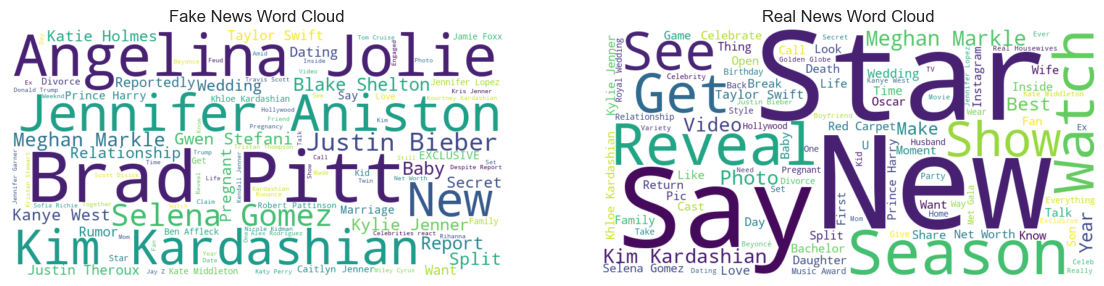

In [192]:
# Cell 14: Word clouds for visual comparison
fake_text = ' '.join(df[df['label'] == 1][text_col].astype(str))
real_text = ' '.join(df[df['label'] == 0][text_col].astype(str))

wc_fake = WordCloud(stopwords=stop_words, max_words=100, background_color='white',
                    width=800, height=400, random_state=42).generate(fake_text)
wc_real = WordCloud(stopwords=stop_words, max_words=100, background_color='white',
                    width=800, height=400, random_state=42).generate(real_text)

plt.figure(figsize=(14,7))
plt.subplot(1,2,1)
plt.imshow(wc_fake, interpolation='bilinear')
plt.title('Fake News Word Cloud')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(wc_real, interpolation='bilinear')
plt.title('Real News Word Cloud')
plt.axis('off')
plt.show()

In [194]:
# Cell 15: Top bigrams for each class
def get_top_ngrams(corpus, ngram_range=(2,2), top_n=20):
    """Extract most frequent n-grams from a text corpus."""
    vec = CountVectorizer(ngram_range=ngram_range, stop_words='english')
    bow = vec.fit_transform(corpus.astype(str))
    freq = bow.sum(axis=0).A1
    ngrams = {idx: word for word, idx in vec.vocabulary_.items()}
    sorted_ngrams = sorted(zip(ngrams.values(), freq), key=lambda x: x[1], reverse=True)
    return sorted_ngrams[:top_n]

print("Top 20 bigrams in FAKE news:")
for bg, count in get_top_ngrams(df[df['label'] == 1][text_col], (2,2)):
    print(f"{bg}: {count}")

print("\nTop 20 bigrams in REAL news:")
for bg, count in get_top_ngrams(df[df['label'] == 0][text_col], (2,2)):
    print(f"{bg}: {count}")

Top 20 bigrams in FAKE news:
royal pregnancy: 386
mother day: 284
ca fight: 266
official royal: 240
heather locklear: 232
went globes: 204
wife jenna: 200
ditches jennifer: 172
jolie search: 150
time france: 148
daughter dakota: 142
hoping selena: 123
alum hospitalized: 122
pregnant day: 119
fight restaurant: 112
wants wants: 105
thompson baby: 97
williams debuts: 94
cruise envious: 85
instagram unfollowing: 85

Top 20 bigrams in REAL news:
stars mirrorball: 316
worries husband: 308
jail 10: 240
female fronted: 207
mom ruining: 205
status jamie: 203
drunk uncooperative: 196
embarrasses mom: 163
brushing homemade: 144
new discovery: 132
2017 espy: 124
recovered 2015: 120
behavior ruins: 118
colbert late: 115
apologizes skipping: 114
friends pals: 111
screaming match: 106
nightmares collided: 102
feels perfect: 101
alba family: 99


In [196]:
# Cell 16: Feature extraction – TF‑IDF vectorisation
# We'll use unigrams and bigrams, limit to 5000 features to keep the matrix manageable
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words='english',
    ngram_range=(1, 2)      # includes unigrams and bigrams
)

X_tfidf = tfidf_vectorizer.fit_transform(df[text_col].astype(str))
y = df['label'].values

print("TF‑IDF feature matrix shape:", X_tfidf.shape)
print("First 5 feature names:", tfidf_vectorizer.get_feature_names_out()[:5].tolist())

TF‑IDF feature matrix shape: (22140, 5000)
First 5 feature names: ['000', '10', '10 million', '10 things', '10 year']


Title Length Statistics:
count    22140.000000
mean        68.704652
std         22.756737
min         10.000000
25%         55.000000
50%         68.000000
75%         84.000000
max        200.000000
Name: title_len, dtype: float64


METHOD 1: IQR Method
Q1: 55.00
Q3: 84.00
IQR: 29.00
Lower bound: 11.50
Upper bound: 127.50
Number of outliers: 313 (1.41%)
Outlier range: < 12 or > 128 characters

METHOD 2: Z-Score Method
Z-score threshold: 3
Number of outliers: 85 (0.38%)

METHOD 3: Percentile Method
Lower 1th percentile: 13.00
Upper 99th percentile: 123.61
Number of outliers: 443 (2.00%)

METHOD 4: Modified Z-Score (MAD)
Median: 68.00
MAD: 14.00
Threshold: 3.5
Number of outliers: 61 (0.28%)


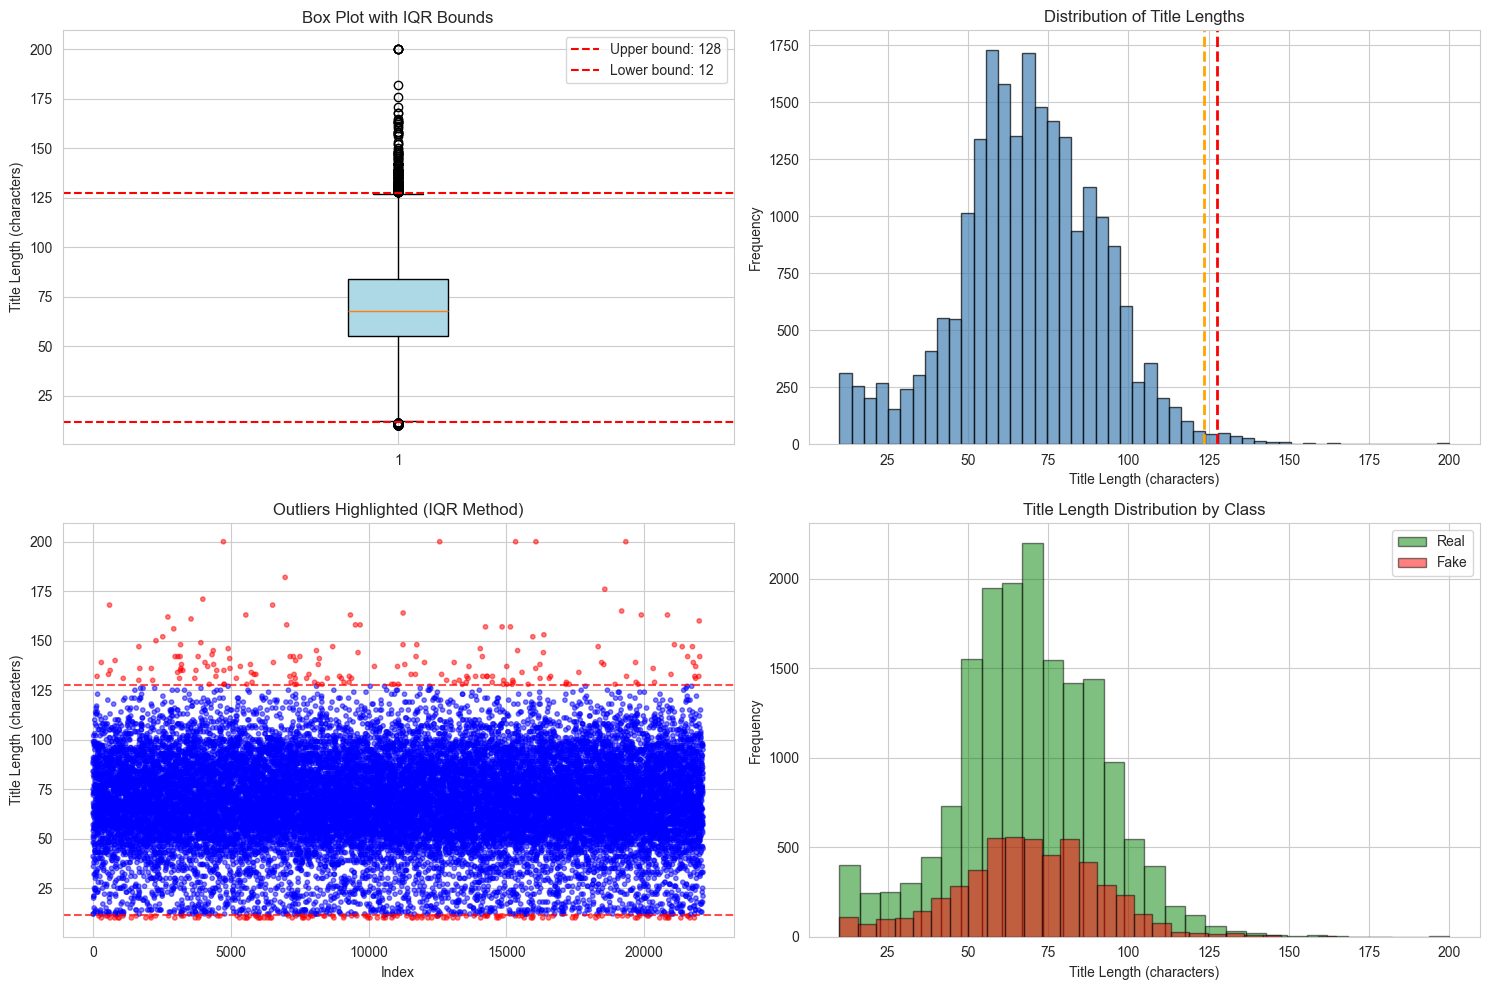


SAMPLE OF OUTLIERS (IQR Method)


,Title,Length,Label
147,People can't stop wondering if Selena Gomez re...,132,1
214,Spice Girls,11,0
301,Alexa Vega,10,0
302,Khloe Kardashian finally opened up about Trist...,139,1
465,Joey Potter,11,0
542,Jenna Dewan,11,0
562,"Contagious Workouts, the Robbery and Kanye Wes...",133,0
599,Caitlyn Jenner: her confrontation with the Kar...,168,1
619,Gigi Hadid,10,0
623,Nikki Bella Awkwardly Demotes BFFs From Brides...,135,0



OUTLIER DETECTION SUMMARY


,Method,Total Outliers,Percentage
0,IQR,313,1.41%
1,Z-Score,85,0.38%
2,Percentile (1-99),443,2.00%
3,Modified Z-Score (MAD),61,0.28%


In [198]:
# Cell: Outlier Detection for Text Length in Title Column
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check if title column exists
if 'title' in df.columns:
    # Calculate title length
    df['title_len'] = df['title'].astype(str).apply(len)
    
    print("Title Length Statistics:")
    print(df['title_len'].describe())
    print("\n")
    
    # ============================================
    # METHOD 1: IQR (Interquartile Range) Method
    # ============================================
    Q1 = df['title_len'].quantile(0.25)
    Q3 = df['title_len'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound_iqr = Q1 - 1.5 * IQR
    upper_bound_iqr = Q3 + 1.5 * IQR
    
    outliers_iqr = df[(df['title_len'] < lower_bound_iqr) | (df['title_len'] > upper_bound_iqr)]
    
    print("="*50)
    print("METHOD 1: IQR Method")
    print("="*50)
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound_iqr:.2f}")
    print(f"Upper bound: {upper_bound_iqr:.2f}")
    print(f"Number of outliers: {len(outliers_iqr)} ({len(outliers_iqr)/len(df)*100:.2f}%)")
    print(f"Outlier range: < {lower_bound_iqr:.0f} or > {upper_bound_iqr:.0f} characters")
    
    # ============================================
    # METHOD 2: Z-Score Method
    # ============================================
    from scipy import stats
    
    z_scores = np.abs(stats.zscore(df['title_len'].dropna()))
    threshold_z = 3
    outliers_zscore = df.iloc[df['title_len'].dropna().index][z_scores > threshold_z]
    
    print("\n" + "="*50)
    print("METHOD 2: Z-Score Method")
    print("="*50)
    print(f"Z-score threshold: {threshold_z}")
    print(f"Number of outliers: {len(outliers_zscore)} ({len(outliers_zscore)/len(df)*100:.2f}%)")
    
    # ============================================
    # METHOD 3: Percentile Method
    # ============================================
    lower_percentile = 1
    upper_percentile = 99
    
    lower_bound_pct = df['title_len'].quantile(lower_percentile/100)
    upper_bound_pct = df['title_len'].quantile(upper_percentile/100)
    
    outliers_percentile = df[(df['title_len'] < lower_bound_pct) | (df['title_len'] > upper_bound_pct)]
    
    print("\n" + "="*50)
    print("METHOD 3: Percentile Method")
    print("="*50)
    print(f"Lower {lower_percentile}th percentile: {lower_bound_pct:.2f}")
    print(f"Upper {upper_percentile}th percentile: {upper_bound_pct:.2f}")
    print(f"Number of outliers: {len(outliers_percentile)} ({len(outliers_percentile)/len(df)*100:.2f}%)")
    
    # ============================================
    # METHOD 4: Modified Z-Score (MAD) - Robust to outliers
    # ============================================
    median = df['title_len'].median()
    mad = np.median(np.abs(df['title_len'] - median))
    modified_z_scores = 0.6745 * (df['title_len'] - median) / mad
    threshold_mad = 3.5
    outliers_mad = df[np.abs(modified_z_scores) > threshold_mad]
    
    print("\n" + "="*50)
    print("METHOD 4: Modified Z-Score (MAD)")
    print("="*50)
    print(f"Median: {median:.2f}")
    print(f"MAD: {mad:.2f}")
    print(f"Threshold: {threshold_mad}")
    print(f"Number of outliers: {len(outliers_mad)} ({len(outliers_mad)/len(df)*100:.2f}%)")
    
    # ============================================
    # VISUALIZATION
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Box plot with IQR outliers highlighted
    ax1 = axes[0, 0]
    bp = ax1.boxplot(df['title_len'].dropna(), vert=True, patch_artist=True)
    bp['boxes'][0].set_facecolor('lightblue')
    ax1.axhline(y=upper_bound_iqr, color='red', linestyle='--', label=f'Upper bound: {upper_bound_iqr:.0f}')
    ax1.axhline(y=lower_bound_iqr, color='red', linestyle='--', label=f'Lower bound: {lower_bound_iqr:.0f}')
    ax1.set_title('Box Plot with IQR Bounds')
    ax1.set_ylabel('Title Length (characters)')
    ax1.legend()
    
    # Histogram with KDE
    ax2 = axes[0, 1]
    ax2.hist(df['title_len'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax2.axvline(x=upper_bound_iqr, color='red', linestyle='--', linewidth=2)
    ax2.axvline(x=upper_bound_pct, color='orange', linestyle='--', linewidth=2)
    ax2.set_title('Distribution of Title Lengths')
    ax2.set_xlabel('Title Length (characters)')
    ax2.set_ylabel('Frequency')
    
    # Scatter plot (index vs length) with outliers highlighted
    ax3 = axes[1, 0]
    colors = np.where((df['title_len'] >= lower_bound_iqr) & (df['title_len'] <= upper_bound_iqr), 'blue', 'red')
    ax3.scatter(range(len(df)), df['title_len'], c=colors, alpha=0.5, s=10)
    ax3.axhline(y=upper_bound_iqr, color='red', linestyle='--', alpha=0.7)
    ax3.axhline(y=lower_bound_iqr, color='red', linestyle='--', alpha=0.7)
    ax3.set_title('Outliers Highlighted (IQR Method)')
    ax3.set_xlabel('Index')
    ax3.set_ylabel('Title Length (characters)')
    
    # Distribution by label
    ax4 = axes[1, 1]
    for label_val, color, name in [(0, 'green', 'Real'), (1, 'red', 'Fake')]:
        subset = df[df['label'] == label_val]
        ax4.hist(subset['title_len'], bins=30, alpha=0.5, color=color, label=name, edgecolor='black')
    ax4.set_title('Title Length Distribution by Class')
    ax4.set_xlabel('Title Length (characters)')
    ax4.set_ylabel('Frequency')
    ax4.legend()
    
    plt.tight_layout()
    plt.show()
    
    # ============================================
    # SHOW SAMPLE OUTLIERS
    # ============================================
    print("\n" + "="*50)
    print("SAMPLE OF OUTLIERS (IQR Method)")
    print("="*50)
    if len(outliers_iqr) > 0:
        display(outliers_iqr[['title', 'title_len', 'label']].head(10)
               .rename(columns={'title': 'Title', 'title_len': 'Length', 'label': 'Label'}))
    else:
        print("No outliers found with IQR method.")
    
    # ============================================
    # SUMMARY TABLE
    # ============================================
    print("\n" + "="*50)
    print("OUTLIER DETECTION SUMMARY")
    print("="*50)
    summary_data = {
        'Method': ['IQR', 'Z-Score', 'Percentile (1-99)', 'Modified Z-Score (MAD)'],
        'Total Outliers': [
            len(outliers_iqr),
            len(outliers_zscore),
            len(outliers_percentile),
            len(outliers_mad)
        ],
        'Percentage': [
            f"{len(outliers_iqr)/len(df)*100:.2f}%",
            f"{len(outliers_zscore)/len(df)*100:.2f}%",
            f"{len(outliers_percentile)/len(df)*100:.2f}%",
            f"{len(outliers_mad)/len(df)*100:.2f}%"
        ]
    }
    summary_df = pd.DataFrame(summary_data)
    display(summary_df)
    
else:
    print("Error: 'title' column not found in the dataset.")
    print("Available columns:", df.columns.tolist())

In [200]:
# Optional Cell: Create outlier flag and filter dataset
# Add outlier flags to the dataset
df['is_outlier_title_len_iqr'] = (df['title_len'] < lower_bound_iqr) | (df['title_len'] > upper_bound_iqr)
df['is_outlier_title_len_zscore'] = z_scores > threshold_z

print("Sample data with outlier flags:")
display(df[['title', 'title_len', 'is_outlier_title_len_iqr', 'label']].sample(20))

# Optional: Filter out outliers
df_no_outliers = df[~df['is_outlier_title_len_iqr']]
print(f"\nOriginal dataset shape: {df.shape}")
print(f"Dataset without title length outliers: {df_no_outliers.shape}")

Sample data with outlier flags:


,title,title_len,is_outlier_title_len_iqr,label
10990,Rachel Lindsay Is Obsessed With This LA-Based ...,59,False,0
19343,Andrew Garfield Faces Backlash After Saying 'I...,100,False,0
16167,"Allison Janney Feeling ""Pretty Overwhelmed"" at...",94,False,0
5105,Lady Gaga Swigs Vinegar Diet For Bradley Cooper,47,False,1
16428,Miley Cyrus Returns With New Single ‘Nothing B...,65,False,0
12145,Lady Antebellum's Hillary Scott Returns to the...,83,False,0
446,Who is Cherry Seaborn? Ed Sheeran’s fiancée an...,90,False,0
13344,Chris Soules' Isolated World After The Bachelo...,115,False,0
12121,Beyonce Stranded by Flying Stage Malfunction i...,72,False,0
1925,2017 Billboard Music Awards: The 5 Biggest Jaw...,55,False,0



Original dataset shape: (22140, 8)
Dataset without title length outliers: (21827, 8)


In [202]:
# Optional Cell: Analyze outlier characteristics
print("Outlier analysis by class:")
print("="*50)
for label_val, label_name in [(0, 'Real'), (1, 'Fake')]:
    total_in_class = len(df[df['label'] == label_val])
    outliers_in_class = len(outliers_iqr[outliers_iqr['label'] == label_val])
    print(f"{label_name} news:")
    print(f"  Total articles: {total_in_class}")
    print(f"  Outliers: {outliers_in_class} ({outliers_in_class/total_in_class*100:.2f}%)")
    print(f"  Mean title length: {df[df['label']==label_val]['title_len'].mean():.2f}")
    print(f"  Outlier mean title length: {outliers_iqr[outliers_iqr['label']==label_val]['title_len'].mean() if outliers_in_class > 0 else 'N/A'}")

Outlier analysis by class:
Real news:
  Total articles: 16817
  Outliers: 224 (1.33%)
  Mean title length: 68.76
  Outlier mean title length: 78.16964285714286
Fake news:
  Total articles: 5323
  Outliers: 89 (1.67%)
  Mean title length: 68.53
  Outlier mean title length: 97.69662921348315


REMOVING OUTLIERS: PERCENTILE METHOD (1-99)
Lower bound (1st percentile): 13.00 characters
Upper bound (99th percentile): 123.61 characters
Acceptable range: 13.00 - 123.61 characters

Total outliers detected: 443 (2.00%)
  - Fake news outliers: 121
  - Real news outliers: 322

SAMPLE OF ROWS TO BE REMOVED


,Title,Length,Label
10,Richard Gere,12,1
11,Harry Hamlin,12,0
147,People can't stop wondering if Selena Gomez re...,132,1
214,Spice Girls,11,0
273,John Mahoney,12,0
301,Alexa Vega,10,0
302,Khloe Kardashian finally opened up about Trist...,139,1
405,Travis Scott,12,0
465,Joey Potter,11,0
542,Jenna Dewan,11,0



DATASET AFTER REMOVING OUTLIERS
Original shape: (22140, 8)
New shape: (21697, 8)
Rows removed: 443 (2.00%)

Class distribution after removal:
Real news (0): 16495 (76.02%)
Fake news (1): 5202 (23.98%)

Title length statistics after removal:
count    21697.000000
mean        68.587731
std         21.070771
min         13.000000
25%         56.000000
50%         68.000000
75%         83.000000
max        123.000000
Name: title_len, dtype: float64


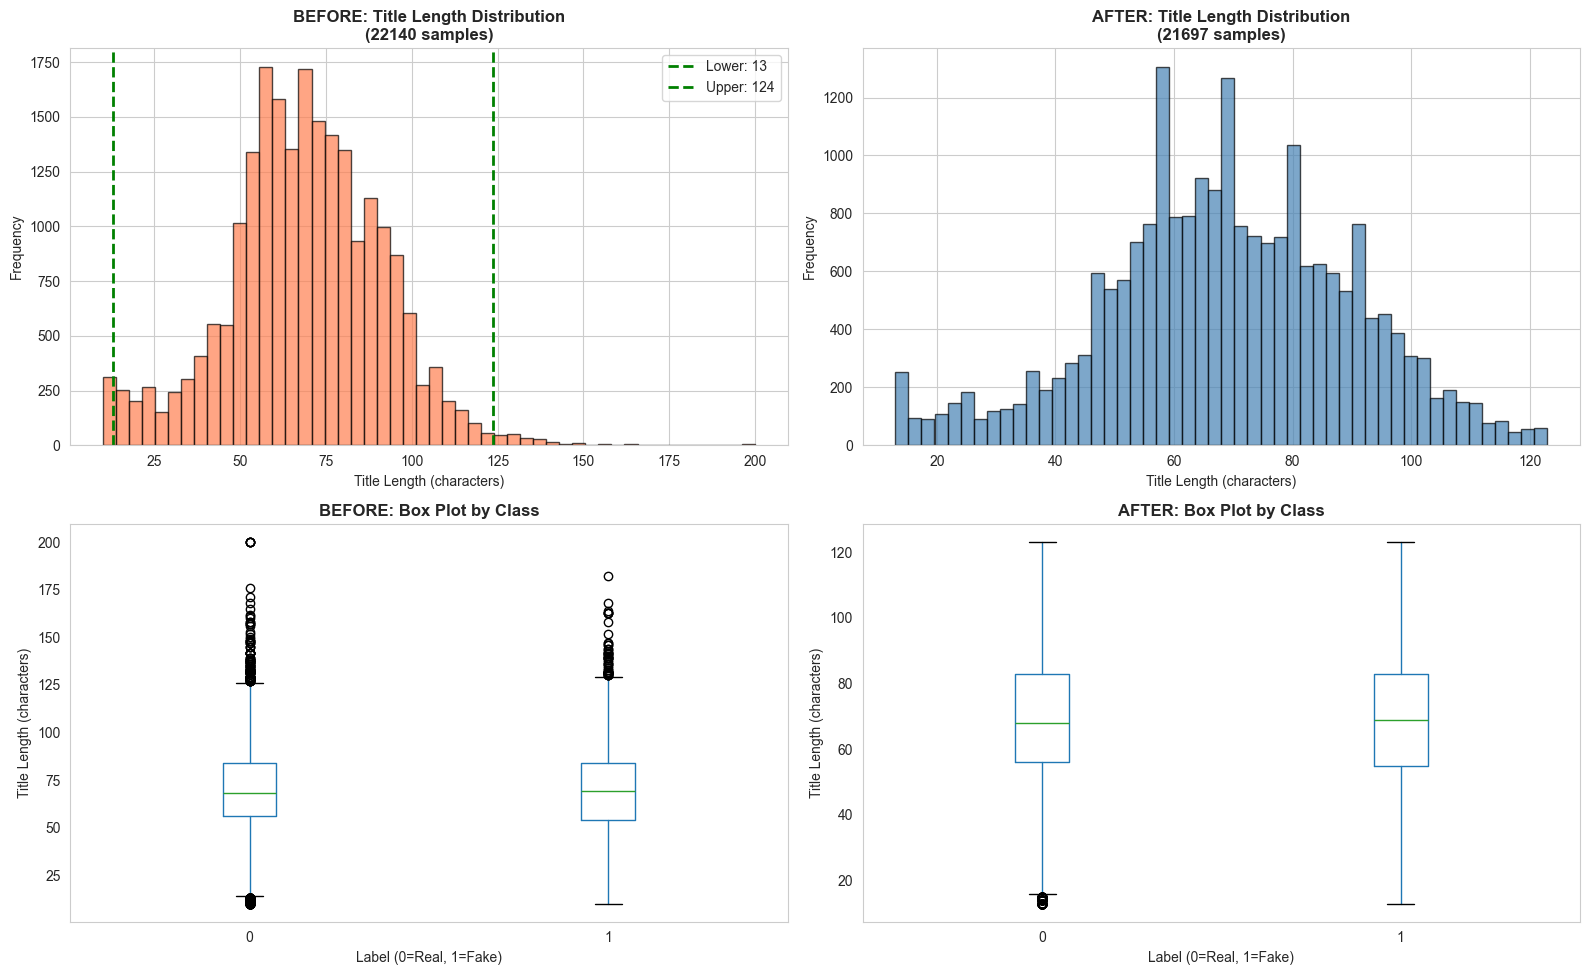


VERIFICATION
✓ SUCCESS: No outliers remaining in the cleaned dataset.

Cleaned dataset ready for use!
Variable 'df_clean' now contains the dataset without title length outliers.


In [204]:
# Cell: Remove Outliers Using Percentile (1-99) Method
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check if title column exists and title_len has been calculated
if 'title' in df.columns and 'title_len' in df.columns:
    
    # Calculate percentile bounds
    lower_percentile = 1
    upper_percentile = 99
    
    lower_bound = df['title_len'].quantile(lower_percentile/100)
    upper_bound = df['title_len'].quantile(upper_percentile/100)
    
    print("="*60)
    print("REMOVING OUTLIERS: PERCENTILE METHOD (1-99)")
    print("="*60)
    print(f"Lower bound (1st percentile): {lower_bound:.2f} characters")
    print(f"Upper bound (99th percentile): {upper_bound:.2f} characters")
    print(f"Acceptable range: {lower_bound:.2f} - {upper_bound:.2f} characters")
    
    # Identify outliers
    outlier_mask = (df['title_len'] < lower_bound) | (df['title_len'] > upper_bound)
    num_outliers = outlier_mask.sum()
    num_removed_fake = outlier_mask[df['label'] == 1].sum()
    num_removed_real = outlier_mask[df['label'] == 0].sum()
    
    print(f"\nTotal outliers detected: {num_outliers} ({num_outliers/len(df)*100:.2f}%)")
    print(f"  - Fake news outliers: {num_removed_fake}")
    print(f"  - Real news outliers: {num_removed_real}")
    
    # Show sample of rows being removed
    print("\n" + "="*60)
    print("SAMPLE OF ROWS TO BE REMOVED")
    print("="*60)
    outliers_df = df[outlier_mask]
    if len(outliers_df) > 0:
        display(outliers_df[['title', 'title_len', 'label']].head(10)
               .rename(columns={'title': 'Title', 'title_len': 'Length', 'label': 'Label'}))
    else:
        print("No outliers to remove!")
    
    # Save original shape for comparison
    original_shape = df.shape
    
    # Remove outliers
    df_clean = df[~outlier_mask].copy()
    
    # Reset index after removal
    df_clean = df_clean.reset_index(drop=True)
    
    print("\n" + "="*60)
    print("DATASET AFTER REMOVING OUTLIERS")
    print("="*60)
    print(f"Original shape: {original_shape}")
    print(f"New shape: {df_clean.shape}")
    print(f"Rows removed: {original_shape[0] - df_clean.shape[0]} ({(original_shape[0] - df_clean.shape[0])/original_shape[0]*100:.2f}%)")
    
    # Check class distribution after removal
    print("\nClass distribution after removal:")
    print(f"Real news (0): {df_clean[df_clean['label']==0].shape[0]} ({df_clean[df_clean['label']==0].shape[0]/df_clean.shape[0]*100:.2f}%)")
    print(f"Fake news (1): {df_clean[df_clean['label']==1].shape[0]} ({df_clean[df_clean['label']==1].shape[0]/df_clean.shape[0]*100:.2f}%)")
    
    # Title length statistics after removal
    print("\nTitle length statistics after removal:")
    print(df_clean['title_len'].describe())
    
    # ============================================
    # VISUALIZATION: Before vs After
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    # Before - Distribution
    ax1 = axes[0, 0]
    ax1.hist(df['title_len'], bins=50, edgecolor='black', alpha=0.7, color='coral')
    ax1.axvline(x=lower_bound, color='green', linestyle='--', linewidth=2, label=f'Lower: {lower_bound:.0f}')
    ax1.axvline(x=upper_bound, color='green', linestyle='--', linewidth=2, label=f'Upper: {upper_bound:.0f}')
    ax1.set_title(f'BEFORE: Title Length Distribution\n({original_shape[0]} samples)', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Title Length (characters)')
    ax1.set_ylabel('Frequency')
    ax1.legend()
    
    # After - Distribution
    ax2 = axes[0, 1]
    ax2.hist(df_clean['title_len'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax2.set_title(f'AFTER: Title Length Distribution\n({df_clean.shape[0]} samples)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Title Length (characters)')
    ax2.set_ylabel('Frequency')
    
    # Before - Box plot by class
    ax3 = axes[1, 0]
    df.boxplot(column='title_len', by='label', ax=ax3, grid=False)
    ax3.set_title('BEFORE: Box Plot by Class', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Label (0=Real, 1=Fake)')
    ax3.set_ylabel('Title Length (characters)')
    ax3.get_figure().suptitle('')  # Remove pandas default title
    
    # After - Box plot by class
    ax4 = axes[1, 1]
    df_clean.boxplot(column='title_len', by='label', ax=ax4, grid=False)
    ax4.set_title('AFTER: Box Plot by Class', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Label (0=Real, 1=Fake)')
    ax4.set_ylabel('Title Length (characters)')
    ax4.get_figure().suptitle('')  # Remove pandas default title
    
    plt.tight_layout()
    plt.show()
    
    # ============================================
    # VERIFICATION: Check no outliers remain
    # ============================================
    remaining_outliers = df_clean[(df_clean['title_len'] < lower_bound) | (df_clean['title_len'] > upper_bound)]
    
    print("\n" + "="*60)
    print("VERIFICATION")
    print("="*60)
    if len(remaining_outliers) == 0:
        print("✓ SUCCESS: No outliers remaining in the cleaned dataset.")
    else:
        print(f"⚠ WARNING: {len(remaining_outliers)} outliers still present.")
    
    print(f"\nCleaned dataset ready for use!")
    print(f"Variable 'df_clean' now contains the dataset without title length outliers.")
    
    # Optional: Overwrite original df
    # Uncomment the next line to replace df with the cleaned version
    # df = df_clean
    
else:
    print("Error: 'title' column not found or 'title_len' not calculated.")
    print("Please run the title length calculation first:")
    print("  df['title_len'] = df['title'].astype(str).apply(len)")
    if 'title' not in df.columns:
        print("Available columns:", df.columns.tolist())

In [212]:
df_clean.head()

,title,label,text_len,word_count,unique_words,title_len,is_outlier_title_len_iqr,is_outlier_title_len_zscore
0,Lea Michele’s Hairstylist’s Mixes Texture Spra...,0,88,13,13,88,False,False
1,"Thomas Markle on Prince Harry, politics, and m...",1,84,12,12,84,False,False
2,2019 SAG Award Nominations: See Full List of N...,0,63,11,11,63,False,False
3,See Meghan Markle’s royal coat of arms and all...,0,75,14,13,75,False,False
4,Kylie Jenner visits shaman in Life of Kylie se...,0,57,10,9,57,False,False


In [216]:
#drop all columns except title and label
df_clean.drop(columns=['text_len', 'word_count', 'unique_words', 'title_len','is_outlier_title_len_iqr','is_outlier_title_len_zscore'], inplace=True)

In [218]:
df_clean.head()

,title,label
0,Lea Michele’s Hairstylist’s Mixes Texture Spra...,0
1,"Thomas Markle on Prince Harry, politics, and m...",1
2,2019 SAG Award Nominations: See Full List of N...,0
3,See Meghan Markle’s royal coat of arms and all...,0
4,Kylie Jenner visits shaman in Life of Kylie se...,0


In [220]:
# Cell: Preprocessing Function
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import emoji
from internet_words_remover import words_remover

# Download required NLTK data (run once)
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Initialize NLP tools
stop_words = set(stopwords.words('english'))
wn_lem = WordNetLemmatizer()
punc = str.maketrans('', '', string.punctuation)

def preprocessing(text):
    # 1. Convert to lowercase and strip whitespace
    text = text.lower()
    text = text.strip()
    
    # 2. Remove HTML tags
    text = re.sub(pattern='<.*?>', repl='', string=text)
    
    # 3. Remove URLs
    text = re.sub(pattern=r'https?://\S+|www\.\S+', repl='', string=text)
    
    # 4. Remove punctuation
    text = text.translate(punc)
    
    # 5. Replace chat words
    text = words_remover(text)
    
    # 6. Remove stopwords
    new_text1 = []
    for word in text.split():
        if word not in stop_words:
            new_text1.append(word)
    text = ' '.join(new_text1)
    
    # 7. Convert emojis to text
    text = emoji.demojize(text)
    
    # 8. Lemmatization
    new_text2 = []
    for word in text.split():
        lemmatized_word = wn_lem.lemmatize(word, pos='v')
        new_text2.append(lemmatized_word)
    text = ' '.join(new_text2)
    
    return text

In [222]:
# Apply preprocessing
df_clean['transformed_text'] = df_clean['title'].apply(preprocessing)

print("Preprocessing completed")
print(df_clean.head())

Preprocessing completed
                                               title  label  \
0  Lea Michele’s Hairstylist’s Mixes Texture Spra...      0   
1  Thomas Markle on Prince Harry, politics, and m...      1   
2  2019 SAG Award Nominations: See Full List of N...      0   
3  See Meghan Markle’s royal coat of arms and all...      0   
4  Kylie Jenner visits shaman in Life of Kylie se...      0   

                                    transformed_text  
0  lea michele’ hairstylist’ mix texture spray co...  
1  thomas markle prince harry politics miss daugh...  
2  2019 sag award nominations see full list nomin...  
3  see meghan markle’ royal coat arm symbols hide...  
4  kylie jenner visit shaman life kylie season fi...  


In [232]:
# Cell: Train-Test Split (Corrected)
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df_clean['transformed_text'], 
    df_clean['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [248]:
# Cell: BoW Feature Extraction
from sklearn.feature_extraction.text import CountVectorizer

# Create CountVectorizer
cv = CountVectorizer()

# Fit and transform on training data, transform on test data
X_train_bow = cv.fit_transform(X_train)
X_test_bow = cv.transform(X_test)

print("BoW feature extraction completed")
print("X_train shape:", X_train_bow.shape)
print("X_test shape:", X_test_bow.shape)

BoW feature extraction completed
X_train shape: (17357, 14369)
X_test shape: (4340, 14369)


In [250]:
import pickle

# Save train vectors
with open("X_train_bow.pkl", "wb") as f:
    pickle.dump(X_train_bow, f)

# Save test vectors
with open("X_test_bow.pkl", "wb") as f:
    pickle.dump(X_test_bow, f)

with open("y_train.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("count_vectorizer.pkl", "wb") as f:
    pickle.dump(cv, f)

In [238]:
df_clean.to_csv('gossipcop_clean.csv', index=False)

In [253]:
# Cell: Import Required Libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [255]:
# Cell: Traditional ML Evaluation Pipeline on BoW Features
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Define parameter grid for each model
param_grid = {
    "LR": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM Linear": {
        "model": SVC(kernel="linear", random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM RBF": {
        "model": SVC(kernel="rbf", random_state=42),
        "params": {"C": [0.5, 1, 2, 5], "gamma": ["scale", "auto", 0.1]}
    },
    "Multinomial NB": {
        "model": MultinomialNB(),
        "params": {"alpha": [0.1, 0.3, 0.5, 1.0, 2.0]}
    },
    "RF": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    }
}

print("MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION")

# STEP 1: Hyperparameter tuning
print("\nTuning hyperparameters with 5-fold CV on training data...")

results = []
best_models = {}

for model_name, model_params in param_grid.items():
    print("Tuning:", model_name)
    
    # Create Stratified K-Fold
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # GridSearchCV
    grid = GridSearchCV(
        estimator=model_params["model"],
        param_grid=model_params["params"],
        cv=skf,
        scoring="accuracy",
        n_jobs=-1,
        verbose=0
    )
    
    # Fit on training data
    grid.fit(X_train_bow, y_train)
    
    # Store best model
    best_models[model_name] = grid.best_estimator_
    
    # Store results
    results.append({
        "Model": model_name,
        "Best Params": grid.best_params_,
        "Train CV Accuracy": round(grid.best_score_, 4),
        "Best Estimator": grid.best_estimator_
    })
    
    print("Best CV Accuracy:", grid.best_score_)
    print("Best Params:", grid.best_params_)

# STEP 2: Select best model based on CV
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="Train CV Accuracy", ascending=False)

print("MODEL RANKING (based on 5-fold CV)")
print(df_results[["Model", "Train CV Accuracy", "Best Params"]])

best_model_name = df_results.iloc[0]["Model"]
best_model = best_models[best_model_name]

print("\nSELECTED BEST MODEL:", best_model_name)
print("Best CV Score:", df_results.iloc[0]['Train CV Accuracy'])

# STEP 3: Retrain best model on full training data
print("RETRAINING BEST MODEL ON FULL TRAINING DATA")

best_model.fit(X_train_bow, y_train)
print("Model retrained on full training data")

# STEP 4: Evaluate on test set
print("FINAL EVALUATION ON TEST SET (ONE TIME ONLY!)")

y_pred = best_model.predict(X_test_bow)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="binary")

print("\nFINAL TEST RESULTS:")
print("Test Accuracy:", test_accuracy)
print("Test F1 Score:", test_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# STEP 5: Compare all models on test set
print("COMPARISON WITH ALL MODELS ON TEST SET")

comparison_results = []

for model_name, estimator in best_models.items():
    estimator.fit(X_train_bow, y_train)
    y_pred_model = estimator.predict(X_test_bow)
    
    acc = accuracy_score(y_test, y_pred_model)
    f1 = f1_score(y_test, y_pred_model, average="binary")
    
    comparison_results.append({
        "Model": model_name,
        "Test Accuracy": acc,
        "Test F1": f1
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(by=["Test F1", "Test Accuracy"], ascending=False)

print("TEST SET PERFORMANCE OF ALL MODELS")
print(comparison_df)

best_test_model_name = comparison_df.iloc[0]["Model"]
best_test_f1_score = comparison_df.iloc[0]["Test F1"]
best_test_accuracy_score = comparison_df.iloc[0]["Test Accuracy"]

print("BEST MODEL BASED ON TEST SET PERFORMANCE")
print("Best Test Model:", best_test_model_name)
print("Test Accuracy:", best_test_accuracy_score)
print("Test F1 Score:", best_test_f1_score)

MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION

Tuning hyperparameters with 5-fold CV on training data...
Tuning: LR
Best CV Accuracy: 0.8461141160398137
Best Params: {'C': 0.5}
Tuning: SVM Linear
Best CV Accuracy: 0.8461139832741864
Best Params: {'C': 0.1}
Tuning: SVM RBF
Best CV Accuracy: 0.8527976870900031
Best Params: {'C': 2, 'gamma': 0.1}
Tuning: Multinomial NB
Best CV Accuracy: 0.8356287348630589
Best Params: {'alpha': 2.0}
Tuning: RF
Best CV Accuracy: 0.8442130948066069
Best Params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
MODEL RANKING (based on 5-fold CV)
            Model  Train CV Accuracy  \
2         SVM RBF             0.8528   
0              LR             0.8461   
1      SVM Linear             0.8461   
4              RF             0.8442   
3  Multinomial NB             0.8356   

                                         Best Params  
2                             {'C': 2, 'gamma': 0.1}  
0                                         {'C': 

In [258]:
# Cell: Undersample majority class to balance dataset
import pandas as pd

# Assume df_clean is your current DataFrame with 'label' column (0=Real, 1=Fake)
print("Original class distribution:")
print(df_clean['label'].value_counts())

# Separate classes
df_class_0 = df_clean[df_clean['label'] == 0]   # majority class (adjust if Fake is majority)
df_class_1 = df_clean[df_clean['label'] == 1]

# Find minority count
minority_count = min(len(df_class_0), len(df_class_1))
print(f"\nMinority class count: {minority_count}")

# Undersample the majority class
if len(df_class_0) > minority_count:
    df_class_0_under = df_class_0.sample(n=minority_count, random_state=42)
else:
    df_class_0_under = df_class_0

if len(df_class_1) > minority_count:
    df_class_1_under = df_class_1.sample(n=minority_count, random_state=42)
else:
    df_class_1_under = df_class_1

# Combine back
df_balanced = pd.concat([df_class_0_under, df_class_1_under], ignore_index=True)
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print("\nBalanced class distribution:")
print(df_balanced['label'].value_counts())
print(f"New dataset shape: {df_balanced.shape}")

# Optional: overwrite df_clean for subsequent steps
# df_clean = df_balanced

Original class distribution:
label
0    16495
1     5202
Name: count, dtype: int64

Minority class count: 5202

Balanced class distribution:
label
1    5202
0    5202
Name: count, dtype: int64
New dataset shape: (10404, 3)


### This code for balanced (undersampled)

In [321]:
df_balanced.head()

,title,label,transformed_text
0,US report: Meghan Markle's rising popularity c...,1,us report meghan markles rise popularity cause...
1,North West Wears Bulletproof Vest to Kanye Wes...,1,north west wear bulletproof vest kanye west’ a...
2,"Confirmed: Meghan & Harry - Yes, it's twins",1,confirm meghan harry yes twin
3,New Bachelor Arie Luyendyk Jr. Is the Biggest ...,0,new bachelor arie luyendyk jr biggest twist su...
4,Botched patient has her face repaired after do...,0,botch patient face repair dog attack


In [323]:
df_balanced.to_csv('gossipcop_bal.csv', index=False)

In [325]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['transformed_text'], 
    df_balanced['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [327]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X_train_bow = cv.fit_transform(X_train)
X_test_bow = cv.transform(X_test)

print("BoW feature extraction completed")
print("X_train shape:", X_train_bow.shape)
print("X_test shape:", X_test_bow.shape)

BoW feature extraction completed
X_train shape: (8323, 9590)
X_test shape: (2081, 9590)


In [329]:
import pickle

# Save train vectors
with open("X_train_bow.pkl", "wb") as f:
    pickle.dump(X_train_bow, f)

# Save test vectors
with open("X_test_bow.pkl", "wb") as f:
    pickle.dump(X_test_bow, f)

with open("y_train_bow.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_bow.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("count_vectorizer.pkl", "wb") as f:
    pickle.dump(cv, f)

In [266]:
# Cell: Traditional ML Evaluation Pipeline on BoW Features
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Define parameter grid for each model
param_grid = {
    "LR": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM Linear": {
        "model": SVC(kernel="linear", random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM RBF": {
        "model": SVC(kernel="rbf", random_state=42),
        "params": {"C": [0.5, 1, 2, 5], "gamma": ["scale", "auto", 0.1]}
    },
    "Multinomial NB": {
        "model": MultinomialNB(),
        "params": {"alpha": [0.1, 0.3, 0.5, 1.0, 2.0]}
    },
    "RF": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    }
}

print("MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION")

# STEP 1: Hyperparameter tuning
print("\nTuning hyperparameters with 5-fold CV on training data...")

results = []
best_models = {}

for model_name, model_params in param_grid.items():
    print("Tuning:", model_name)
    
    # Create Stratified K-Fold
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # GridSearchCV
    grid = GridSearchCV(
        estimator=model_params["model"],
        param_grid=model_params["params"],
        cv=skf,
        scoring="accuracy",
        n_jobs=-1,
        verbose=0
    )
    
    # Fit on training data
    grid.fit(X_train_bow, y_train)
    
    # Store best model
    best_models[model_name] = grid.best_estimator_
    
    # Store results
    results.append({
        "Model": model_name,
        "Best Params": grid.best_params_,
        "Train CV Accuracy": round(grid.best_score_, 4),
        "Best Estimator": grid.best_estimator_
    })
    
    print("Best CV Accuracy:", grid.best_score_)
    print("Best Params:", grid.best_params_)

# STEP 2: Select best model based on CV
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="Train CV Accuracy", ascending=False)

print("MODEL RANKING (based on 5-fold CV)")
print(df_results[["Model", "Train CV Accuracy", "Best Params"]])

best_model_name = df_results.iloc[0]["Model"]
best_model = best_models[best_model_name]

print("\nSELECTED BEST MODEL:", best_model_name)
print("Best CV Score:", df_results.iloc[0]['Train CV Accuracy'])

# STEP 3: Retrain best model on full training data
print("RETRAINING BEST MODEL ON FULL TRAINING DATA")

best_model.fit(X_train_bow, y_train)
print("Model retrained on full training data")

# STEP 4: Evaluate on test set
print("FINAL EVALUATION ON TEST SET (ONE TIME ONLY!)")

y_pred = best_model.predict(X_test_bow)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="binary")

print("\nFINAL TEST RESULTS:")
print("Test Accuracy:", test_accuracy)
print("Test F1 Score:", test_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# STEP 5: Compare all models on test set
print("COMPARISON WITH ALL MODELS ON TEST SET")

comparison_results = []

for model_name, estimator in best_models.items():
    estimator.fit(X_train_bow, y_train)
    y_pred_model = estimator.predict(X_test_bow)
    
    acc = accuracy_score(y_test, y_pred_model)
    f1 = f1_score(y_test, y_pred_model, average="binary")
    
    comparison_results.append({
        "Model": model_name,
        "Test Accuracy": acc,
        "Test F1": f1
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values(by=["Test F1", "Test Accuracy"], ascending=False)

print("TEST SET PERFORMANCE OF ALL MODELS")
print(comparison_df)

best_test_model_name = comparison_df.iloc[0]["Model"]
best_test_f1_score = comparison_df.iloc[0]["Test F1"]
best_test_accuracy_score = comparison_df.iloc[0]["Test Accuracy"]

print("BEST MODEL BASED ON TEST SET PERFORMANCE")
print("Best Test Model:", best_test_model_name)
print("Test Accuracy:", best_test_accuracy_score)
print("Test F1 Score:", best_test_f1_score)

MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION

Tuning hyperparameters with 5-fold CV on training data...
Tuning: LR
Best CV Accuracy: 0.7861347164472164
Best Params: {'C': 0.5}
Tuning: SVM Linear
Best CV Accuracy: 0.7875778182028182
Best Params: {'C': 0.1}
Tuning: SVM RBF
Best CV Accuracy: 0.7895008229383229
Best Params: {'C': 2, 'gamma': 0.1}
Tuning: Multinomial NB
Best CV Accuracy: 0.7897424347424348
Best Params: {'alpha': 0.5}
Tuning: RF
Best CV Accuracy: 0.7753220287595288
Best Params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
MODEL RANKING (based on 5-fold CV)
            Model  Train CV Accuracy  \
3  Multinomial NB             0.7897   
2         SVM RBF             0.7895   
1      SVM Linear             0.7876   
0              LR             0.7861   
4              RF             0.7753   

                                         Best Params  
3                                     {'alpha': 0.5}  
2                             {'C': 2, 'gamma': 

In [268]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_clean['transformed_text'], 
    df_clean['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [270]:
# Cell: BoW Feature Extraction
from sklearn.feature_extraction.text import CountVectorizer

# Create CountVectorizer
cv = CountVectorizer()

# Fit and transform on training data, transform on test data
X_train_bow = cv.fit_transform(X_train)
X_test_bow = cv.transform(X_test)

print("BoW feature extraction completed")
print("X_train shape:", X_train_bow.shape)
print("X_test shape:", X_test_bow.shape)

BoW feature extraction completed
X_train shape: (17357, 14369)
X_test shape: (4340, 14369)


In [274]:
# Cell: Manual SMOTE (works without imbalanced-learn)
import numpy as np
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import issparse, vstack

def manual_smote(X, y, random_state=42, k_neighbors=5):
    """Apply SMOTE to the minority class of a sparse/dense matrix X."""
    np.random.seed(random_state)
    
    # Separate classes
    class_counts = np.bincount(y)
    minority_class = np.argmin(class_counts)
    majority_class = np.argmax(class_counts)
    
    X_min = X[y == minority_class]
    n_minority = X_min.shape[0]
    n_majority = X[y == majority_class].shape[0]
    n_synthetic = n_majority - n_minority
    
    if n_synthetic <= 0:
        return X, y  # already balanced
    
    # k-NN on minority samples
    nn = NearestNeighbors(n_neighbors=min(k_neighbors+1, n_minority), metric='euclidean')
    nn.fit(X_min)
    distances, indices = nn.kneighbors(X_min)
    
    synthetic_samples = []
    for i in range(n_synthetic):
        # Pick a random minority sample
        idx = np.random.randint(0, n_minority)
        # Pick a random neighbor (skip the first which is itself)
        nn_idx = indices[idx, np.random.randint(1, indices.shape[1])]
        
        # Interpolate
        diff = X_min[nn_idx] - X_min[idx]
        gap = np.random.random()
        new_sample = X_min[idx] + gap * diff
        
        # Convert sparse matrix row to same format
        if issparse(new_sample):
            new_sample = new_sample.tocsr()  # ensure format
        synthetic_samples.append(new_sample)
    
    # Convert to array or stack sparse
    if issparse(X_min):
        synthetic = vstack(synthetic_samples)
    else:
        synthetic = np.array(synthetic_samples)
    
    # Combine
    X_resampled = vstack([X, synthetic]) if issparse(X) else np.vstack([X, synthetic])
    y_resampled = np.hstack([y, np.full(n_synthetic, minority_class)])
    
    return X_resampled, y_resampled

# Usage:
X_train_resampled, y_train_resampled = manual_smote(X_train_bow, y_train, random_state=42)

In [276]:
X_train_resampled.shape

(26504, 14369)

In [278]:
y_train_resampled.shape

(26504,)

In [280]:
# Cell: Hyperparameter tuning on SMOTE-balanced training data
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Define parameter grid (same as before)
param_grid = {
    "LR": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM Linear": {
        "model": SVC(kernel="linear", random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM RBF": {
        "model": SVC(kernel="rbf", random_state=42),
        "params": {"C": [0.5, 1, 2, 5], "gamma": ["scale", "auto", 0.1]}
    },
    "Multinomial NB": {
        "model": MultinomialNB(),
        "params": {"alpha": [0.1, 0.3, 0.5, 1.0, 2.0]}
    },
    "RF": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    }
}

print("MODEL SELECTION WITH SMOTE-BALANCED TRAINING DATA (5-FOLD CV)")

results = []
best_models = {}

for model_name, model_params in param_grid.items():
    print(f"Tuning: {model_name}")
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(
        estimator=model_params["model"],
        param_grid=model_params["params"],
        cv=skf,
        scoring="accuracy",
        n_jobs=-1,
        verbose=0
    )
    
    # Fit on the SMOTE-balanced training data
    grid.fit(X_train_resampled, y_train_resampled)
    
    best_models[model_name] = grid.best_estimator_
    results.append({
        "Model": model_name,
        "Best Params": grid.best_params_,
        "Train CV Accuracy": round(grid.best_score_, 4),
        "Best Estimator": grid.best_estimator_
    })
    
    print(f"  Best CV Accuracy: {grid.best_score_:.4f}")
    print(f"  Best Params: {grid.best_params_}")

# Ranking
df_results = pd.DataFrame(results).sort_values("Train CV Accuracy", ascending=False)
print("\nMODEL RANKING (based on balanced CV):")
print(df_results[["Model", "Train CV Accuracy", "Best Params"]])

best_model_name = df_results.iloc[0]["Model"]
best_model = best_models[best_model_name]
print(f"\nSELECTED BEST MODEL: {best_model_name}")
print(f"Best CV Score: {df_results.iloc[0]['Train CV Accuracy']}")

MODEL SELECTION WITH SMOTE-BALANCED TRAINING DATA (5-FOLD CV)
Tuning: LR
  Best CV Accuracy: 0.8890
  Best Params: {'C': 5}
Tuning: SVM Linear
  Best CV Accuracy: 0.8825
  Best Params: {'C': 1}
Tuning: SVM RBF
  Best CV Accuracy: 0.9380
  Best Params: {'C': 5, 'gamma': 'scale'}
Tuning: Multinomial NB
  Best CV Accuracy: 0.8787
  Best Params: {'alpha': 0.1}
Tuning: RF
  Best CV Accuracy: 0.9117
  Best Params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300}

MODEL RANKING (based on balanced CV):
            Model  Train CV Accuracy  \
2         SVM RBF             0.9380   
4              RF             0.9117   
0              LR             0.8890   
1      SVM Linear             0.8825   
3  Multinomial NB             0.8787   

                                         Best Params  
2                         {'C': 5, 'gamma': 'scale'}  
4  {'max_depth': None, 'min_samples_split': 5, 'n...  
0                                           {'C': 5}  
1                      

In [282]:
print("RETRAINING BEST MODEL ON FULL BALANCED TRAINING DATA")
best_model.fit(X_train_resampled, y_train_resampled)

print("FINAL EVALUATION ON TEST SET (NO SMOTE!)")
y_pred = best_model.predict(X_test_bow)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="binary")

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test F1 Score: {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Real', 'Fake']))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

RETRAINING BEST MODEL ON FULL BALANCED TRAINING DATA
FINAL EVALUATION ON TEST SET (NO SMOTE!)

Test Accuracy: 0.8376
Test F1 Score: 0.6379

Classification Report:
              precision    recall  f1-score   support

        Real       0.86      0.93      0.90      3243
        Fake       0.73      0.57      0.64      1097

    accuracy                           0.84      4340
   macro avg       0.80      0.75      0.77      4340
weighted avg       0.83      0.84      0.83      4340

Confusion Matrix:
[[3014  229]
 [ 476  621]]


In [284]:
# Cell: Compare all tuned models on the original test set
print("COMPARISON OF ALL MODELS ON TEST SET (trained on balanced data)")

comparison_results = []
for model_name, estimator in best_models.items():
    # Each model was already fitted on the resampled training data inside the loop
    # Re-predict on test set
    y_pred_model = estimator.predict(X_test_bow)
    acc = accuracy_score(y_test, y_pred_model)
    f1 = f1_score(y_test, y_pred_model, average="binary")
    comparison_results.append({
        "Model": model_name,
        "Test Accuracy": acc,
        "Test F1": f1
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(["Test F1", "Test Accuracy"], ascending=False)
print(comparison_df)

best_test = comparison_df.iloc[0]
print(f"\nBEST MODEL ON TEST SET: {best_test['Model']}")
print(f"Test Accuracy: {best_test['Test Accuracy']:.4f}")
print(f"Test F1 Score: {best_test['Test F1']:.4f}")

COMPARISON OF ALL MODELS ON TEST SET (trained on balanced data)
            Model  Test Accuracy   Test F1
3  Multinomial NB       0.811290  0.649850
0              LR       0.810369  0.639509
2         SVM RBF       0.837558  0.637904
4              RF       0.837788  0.637487
1      SVM Linear       0.804378  0.636714

BEST MODEL ON TEST SET: Multinomial NB
Test Accuracy: 0.8113
Test F1 Score: 0.6499


In [286]:
df.head()

,title,label,text_len,word_count,unique_words,title_len,is_outlier_title_len_iqr,is_outlier_title_len_zscore
0,Lea Michele’s Hairstylist’s Mixes Texture Spra...,0,88,13,13,88,False,False
1,"Thomas Markle on Prince Harry, politics, and m...",1,84,12,12,84,False,False
2,2019 SAG Award Nominations: See Full List of N...,0,63,11,11,63,False,False
3,See Meghan Markle’s royal coat of arms and all...,0,75,14,13,75,False,False
4,Kylie Jenner visits shaman in Life of Kylie se...,0,57,10,9,57,False,False


In [288]:
df_clean.head()

,title,label,transformed_text
0,Lea Michele’s Hairstylist’s Mixes Texture Spra...,0,lea michele’ hairstylist’ mix texture spray co...
1,"Thomas Markle on Prince Harry, politics, and m...",1,thomas markle prince harry politics miss daugh...
2,2019 SAG Award Nominations: See Full List of N...,0,2019 sag award nominations see full list nomin...
3,See Meghan Markle’s royal coat of arms and all...,0,see meghan markle’ royal coat arm symbols hide...
4,Kylie Jenner visits shaman in Life of Kylie se...,0,kylie jenner visit shaman life kylie season fi...


### Creating Ngram

In [294]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['transformed_text'], 
    df_balanced['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [331]:
from sklearn.feature_extraction.text import CountVectorizer

# N-gram vectorizer with unigrams and bigrams, top 5000 features
ngram_vectorizer = CountVectorizer(ngram_range=(1,2), max_features=5000)

X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)

print("N-gram feature extraction completed")
print("X_train ngram shape:", X_train_ngram.shape)
print("X_test ngram shape:", X_test_ngram.shape)

N-gram feature extraction completed
X_train ngram shape: (8323, 5000)
X_test ngram shape: (2081, 5000)


In [335]:
import pickle

# Save train vectors
with open("X_train_ngram.pkl", "wb") as f:
    pickle.dump(X_train_ngram, f)

# Save test vectors
with open("X_test_ngram.pkl", "wb") as f:
    pickle.dump(X_test_ngram, f)

with open("y_train_ngram.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_ngram.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("ngrams.pkl", "wb") as f:
    pickle.dump(ngram_vectorizer, f)

### Creating TFIDF

In [353]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Simple TF-IDF (unigrams only, no max_features)
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed")
print("TF-IDF X_train shape:", X_train_tfidf.shape)
print("TF-IDF X_test shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed
TF-IDF X_train shape: (8323, 9590)
TF-IDF X_test shape: (2081, 9590)


In [355]:
import pickle

# Save train vectors
with open("X_train_tfidf.pkl", "wb") as f:
    pickle.dump(X_train_tfidf, f)

# Save test vectors
with open("X_test_tfidf.pkl", "wb") as f:
    pickle.dump(X_test_tfidf, f)

with open("y_train_tfidf.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_tfidf.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("tfidf.pkl", "wb") as f:
    pickle.dump(tfidf, f)

### Creating TFIDF (ngram)

In [357]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF with unigrams and bigrams, top 5000 features
tfidf_ngram = TfidfVectorizer(ngram_range=(1,2), max_features=5000)
X_train_tfidf_ngram = tfidf_ngram.fit_transform(X_train)
X_test_tfidf_ngram = tfidf_ngram.transform(X_test)

print("TF-IDF feature extraction completed")
print("TF-IDF ngram X_train shape:", X_train_tfidf_ngram.shape)
print("TF-IDF ngram X_test shape:", X_test_tfidf_ngram.shape)

TF-IDF feature extraction completed
TF-IDF ngram X_train shape: (8323, 5000)
TF-IDF ngram X_test shape: (2081, 5000)


In [361]:
import pickle

# Save train vectors
with open("X_train_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(X_train_tfidf_ngram, f)

# Save test vectors
with open("X_test_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(X_test_tfidf_ngram, f)

with open("y_train_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("tfidf_ngram.pkl", "wb") as f:
    pickle.dump(tfidf_ngram, f)

### Creating pos tagging

In [367]:
# POS tag features combined with Bag-of-Words
import nltk
from nltk import word_tokenize, pos_tag
from collections import Counter
from scipy.sparse import hstack
import pandas as pd

# Ensure required NLTK data is available (run once)
nltk.download('punkt', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Functions to extract POS tags and count features
def get_pos_tags(text):
    tokens = word_tokenize(text)
    return pos_tag(tokens)

def pos_features(pos_tags):
    counts = Counter(tag for (word, tag) in pos_tags)
    feature_dict = {
        'nouns': counts.get('NN',0) + counts.get('NNS',0) + counts.get('NNP',0) + counts.get('NNPS',0),
        'verbs': counts.get('VB',0) + counts.get('VBD',0) + counts.get('VBG',0) + counts.get('VBN',0) +
                 counts.get('VBP',0) + counts.get('VBZ',0),
        'adjectives': counts.get('JJ',0) + counts.get('JJR',0) + counts.get('JJS',0),
        'adverbs': counts.get('RB',0) + counts.get('RBR',0) + counts.get('RBS',0)
    }
    return feature_dict

# Apply POS extraction to training and test texts
print("Extracting POS tags from training data...")
train_pos_tags = X_train.apply(get_pos_tags)
test_pos_tags = X_test.apply(get_pos_tags)

print("Computing POS features...")
train_pos_feat = train_pos_tags.apply(pos_features)
test_pos_feat = test_pos_tags.apply(pos_features)

# Convert the dictionary Series into DataFrames
df_train_pos = pd.DataFrame(list(train_pos_feat))
df_test_pos = pd.DataFrame(list(test_pos_feat))

# Create BoW features (unigrams) using CountVectorizer
bow_vectorizer = CountVectorizer()
X_train_bow_pos = bow_vectorizer.fit_transform(X_train)
X_test_bow_pos = bow_vectorizer.transform(X_test)

# Combine BoW matrix with POS dense features using hstack
X_train_pos_bow = hstack([X_train_bow_pos, df_train_pos.values])
X_test_pos_bow = hstack([X_test_bow_pos, df_test_pos.values])

print("POS + BOW features completed")
print("X_train shape:", X_train_pos_bow.shape)
print("X_test shape:", X_test_pos_bow.shape)

Extracting POS tags from training data...
Computing POS features...
POS + BOW features completed
X_train shape: (8323, 9594)
X_test shape: (2081, 9594)


In [369]:
import pickle

# Save train vectors
with open("X_train_pos_bow.pkl", "wb") as f:
    pickle.dump(X_train_pos_bow, f)

# Save test vectors
with open("X_test_pos_bow.pkl", "wb") as f:
    pickle.dump(X_test_pos_bow, f)

with open("y_train_pos.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_pos.pkl", "wb") as f:
    pickle.dump(y_test, f)